# CS 640 - 2026 Fall - Homework 8 Programming

In this homework, you will implement convolutional and recurrent neural networks to analyze time series data for temperature.

## Instructions

1. Follow the instructions below.
2. Run all the cells before submitting.
3. Submit your notebook and output files in Gradescope.
4. Check the autograder results.

In [2]:
import pandas as pd
import torch
from io import StringIO

### Synthetic Temperature Data

In [3]:
csv_data = """date,mean_temp_c,min_temp_c,max_temp_c
2024-11-01,12.5,9.2,18.3
2024-11-02,13.0,7.7,17.3
2024-11-03,14.9,10.6,18.8
2024-11-04,10.1,5.5,15.6
2024-11-05,7.7,2.7,12.4
2024-11-06,3.9,-0.3,9.7
2024-11-07,8.4,3.7,14.5
2024-11-08,9.9,5.6,14.1
2024-11-09,13.3,7.3,20.2
2024-11-10,10.9,6.5,16.7
2024-11-11,14.3,11.3,17.3
2024-11-12,13.5,11.7,17.8
2024-11-13,8.1,2.9,13.3
2024-11-14,6.4,2.2,11.5
2024-11-15,6.7,2.3,11.8
2024-11-16,10.0,3.9,13.9
2024-11-17,5.6,0.7,11.2
2024-11-18,6.1,2.2,9.5
2024-11-19,6.1,1.9,13.3
2024-11-20,3.6,-2.4,8.1
2024-11-21,3.8,-1.2,6.5
2024-11-22,9.2,5.6,13.6
2024-11-23,5.3,0.3,11.6
2024-11-24,2.0,-2.4,6.1
2024-11-25,1.0,-5.1,7.5
2024-11-26,3.8,-0.3,10.3
2024-11-27,2.6,-3.9,7.3
2024-11-28,4.0,-0.2,7.6
2024-11-29,10.2,5.5,14.2
2024-11-30,7.3,1.9,11.4
2024-12-01,10.1,6.5,15.7
2024-12-02,8.0,4.6,10.3
2024-12-03,10.9,6.4,16.1
2024-12-04,16.5,12.1,19.6
2024-12-05,9.0,5.3,14.4
2024-12-06,11.4,7.3,15.4
2024-12-07,15.2,11.7,19.2
2024-12-08,10.2,4.8,16.4
2024-12-09,10.9,5.8,15.6
2024-12-10,7.1,1.0,10.9
2024-12-11,6.1,1.9,8.8
2024-12-12,6.0,-0.7,10.8
2024-12-13,6.7,1.9,12.0
2024-12-14,9.2,6.1,15.4
2024-12-15,9.9,3.3,16.5
2024-12-16,6.4,2.0,11.3
2024-12-17,1.5,-2.2,5.5
2024-12-18,-1.2,-6.1,4.4
2024-12-19,2.7,-1.0,7.3
2024-12-20,1.4,-4.7,7.4
2024-12-21,-0.9,-7.6,2.6
2024-12-22,0.2,-4.3,7.2
2024-12-23,6.6,1.4,10.9
2024-12-24,6.8,3.0,9.9
2024-12-25,7.5,4.0,11.6
2024-12-26,2.4,-4.4,6.2
2024-12-27,1.0,-4.5,6.1
2024-12-28,4.3,-0.6,7.2
2024-12-29,5.3,-0.2,10.7
2024-12-30,-2.9,-7.3,2.8
2024-12-31,0.6,-5.1,2.9
2025-01-01,0.2,-5.4,7.3
2025-01-02,3.2,-1.5,5.2
2025-01-03,6.1,0.5,8.9
2025-01-04,5.8,0.5,11.3
2025-01-05,2.6,-3.4,9.3
2025-01-06,1.4,-4.5,6.2
2025-01-07,-0.7,-6.4,5.7
2025-01-08,1.2,-2.8,6.1
2025-01-09,0.6,-6.7,8.7
2025-01-10,2.2,-5.3,8.6
2025-01-11,0.7,-2.0,5.8
2025-01-12,3.5,-1.2,6.6
2025-01-13,7.9,2.5,12.9
2025-01-14,6.4,0.4,11.2
2025-01-15,0.4,-5.4,5.4
2025-01-16,-2.2,-7.4,3.6
2025-01-17,-3.6,-8.4,3.4
2025-01-18,4.1,-0.3,10.5
2025-01-19,9.4,3.6,13.3
2025-01-20,-0.4,-5.6,3.6
2025-01-21,-2.2,-5.5,0.5
2025-01-22,-6.8,-12.3,-0.6
2025-01-23,-1.8,-6.3,4.0
2025-01-24,0.2,-2.5,3.3
2025-01-25,-1.9,-5.4,4.6
2025-01-26,3.4,-3.2,9.8
2025-01-27,4.1,2.2,6.1
2025-01-28,4.6,-1.4,8.9
2025-01-29,0.1,-4.6,4.6
2025-01-30,0.3,-3.1,3.0
2025-01-31,-2.6,-8.6,3.6
2025-02-01,-3.3,-4.7,-0.9
2025-02-02,-7.4,-10.5,-3.1
2025-02-03,-3.5,-8.5,0.1
2025-02-04,-0.6,-6.5,3.1
2025-02-05,3.0,-0.9,5.6
2025-02-06,-2.4,-5.6,2.7
2025-02-07,-2.5,-7.9,2.1
2025-02-08,-0.2,-4.5,5.0
2025-02-09,2.1,-2.5,7.5
2025-02-10,1.4,-0.8,5.0
2025-02-11,2.9,-0.3,5.4
2025-02-12,3.7,-1.2,10.0
2025-02-13,4.1,-1.1,9.7
2025-02-14,-0.4,-8.0,5.0
2025-02-15,-1.4,-6.3,3.6
2025-02-16,1.5,-4.6,6.8
2025-02-17,2.8,-3.1,9.4
2025-02-18,3.3,-2.1,9.6
2025-02-19,2.9,-1.4,7.2
2025-02-20,5.2,0.2,8.2
2025-02-21,3.1,-0.8,8.9
2025-02-22,4.2,-0.6,7.8
2025-02-23,7.0,2.9,12.9
2025-02-24,2.3,-1.6,5.7
2025-02-25,-2.9,-8.7,2.1
2025-02-26,1.6,-3.0,5.1
2025-02-27,5.9,3.5,10.1
2025-02-28,9.0,5.4,13.2
2025-03-01,0.7,-5.3,4.5
2025-03-02,-1.5,-2.4,3.0
2025-03-03,-0.9,-6.1,2.0
2025-03-04,6.7,-0.2,9.8
2025-03-05,0.8,-2.6,5.6
2025-03-06,-0.5,-6.5,4.5
2025-03-07,-1.4,-5.8,3.4
2025-03-08,-2.3,-4.9,2.0
2025-03-09,-4.1,-7.5,0.3
2025-03-10,0.7,-3.3,6.2
2025-03-11,-1.1,-6.2,4.9
2025-03-12,3.0,0.7,7.5
2025-03-13,0.6,-3.7,5.7
2025-03-14,-4.4,-11.3,2.7
2025-03-15,1.2,-5.4,6.2
2025-03-16,2.9,-3.1,7.6
2025-03-17,3.3,-2.3,9.2
2025-03-18,0.9,-2.9,2.5
2025-03-19,2.6,-0.0,6.6
2025-03-20,0.6,-2.9,3.7
2025-03-21,3.3,-1.2,6.2
2025-03-22,3.2,-0.3,7.4
2025-03-23,-1.6,-8.4,3.4
2025-03-24,2.8,-3.4,7.7
2025-03-25,7.1,1.7,13.5
2025-03-26,7.6,3.0,12.2
2025-03-27,2.0,-2.7,7.9
2025-03-28,4.4,-2.7,7.3
2025-03-29,4.4,-2.4,8.3
2025-03-30,6.5,2.0,14.0
2025-03-31,5.3,1.4,9.9
2025-04-01,6.3,3.0,9.6
2025-04-02,7.1,1.8,11.4
2025-04-03,7.8,4.5,8.4
2025-04-04,12.3,9.4,15.2
2025-04-05,12.6,10.6,16.7
2025-04-06,9.5,5.7,14.8
2025-04-07,9.9,6.0,14.3
2025-04-08,11.2,7.2,15.5
2025-04-09,6.2,4.6,9.0
2025-04-10,2.6,-1.8,7.3
2025-04-11,5.0,-0.3,9.6
2025-04-12,11.3,7.5,16.4
2025-04-13,14.3,10.9,18.7
2025-04-14,22.0,19.5,27.5
2025-04-15,21.4,16.7,27.3
2025-04-16,13.1,9.0,13.6
2025-04-17,10.2,4.8,15.0
2025-04-18,12.9,8.9,19.3
2025-04-19,10.6,8.5,14.9
2025-04-20,6.7,1.8,11.1
2025-04-21,3.8,0.9,9.7
2025-04-22,8.7,1.3,15.4
2025-04-23,8.8,4.2,11.0
2025-04-24,1.7,-2.1,4.7
2025-04-25,2.5,-2.4,6.4
2025-04-26,4.3,0.1,9.2
2025-04-27,3.4,-1.4,7.9
2025-04-28,10.6,9.9,13.5
2025-04-29,15.7,9.1,21.0
2025-04-30,15.8,9.6,19.4
2025-05-01,16.5,13.3,23.1
2025-05-02,18.6,13.8,23.5
2025-05-03,17.4,14.5,19.7
2025-05-04,14.7,10.9,20.2
2025-05-05,9.7,4.5,16.4
2025-05-06,11.3,6.6,16.9
2025-05-07,14.1,6.7,18.3
2025-05-08,18.6,11.3,23.3
2025-05-09,15.7,11.5,17.4
2025-05-10,18.4,12.8,23.7
2025-05-11,16.8,13.3,22.6
2025-05-12,14.4,10.0,17.5
2025-05-13,13.2,7.9,19.0
2025-05-14,11.7,6.6,16.6
2025-05-15,15.0,10.4,19.4
2025-05-16,18.9,14.5,26.7
2025-05-17,20.0,13.2,24.7
2025-05-18,18.6,13.2,24.5
2025-05-19,15.1,12.1,21.0
2025-05-20,12.4,8.7,16.7
2025-05-21,11.6,6.6,16.8
2025-05-22,16.3,10.9,19.5
2025-05-23,16.5,12.2,17.9
2025-05-24,18.4,15.7,21.2
2025-05-25,18.1,14.1,23.4
2025-05-26,17.9,14.2,23.0
2025-05-27,16.8,12.5,20.4
2025-05-28,20.3,16.6,26.1
2025-05-29,17.6,15.3,21.0
2025-05-30,19.8,16.0,22.5
2025-05-31,20.9,15.6,24.4
2025-06-01,21.1,19.5,25.7
2025-06-02,20.5,15.6,24.4
2025-06-03,18.7,14.7,22.2
2025-06-04,17.4,12.0,19.9
2025-06-05,11.8,5.4,15.7
2025-06-06,10.9,4.5,16.9
2025-06-07,10.2,4.4,15.4
2025-06-08,11.5,9.2,16.5
2025-06-09,16.3,14.9,19.1
2025-06-10,14.9,9.6,17.6
2025-06-11,17.2,14.4,21.3
2025-06-12,17.0,11.6,21.6
2025-06-13,19.9,13.4,26.5
2025-06-14,20.1,16.1,22.1
2025-06-15,16.6,13.2,21.5
2025-06-16,18.4,15.2,23.3
2025-06-17,16.9,12.6,22.4
2025-06-18,17.5,14.1,20.0
2025-06-19,21.8,17.7,27.0
2025-06-20,24.0,19.2,27.5
2025-06-21,22.1,18.1,26.4
2025-06-22,23.9,18.7,28.7
2025-06-23,23.4,18.3,30.0
2025-06-24,24.4,17.6,26.3
2025-06-25,24.4,20.2,27.6
2025-06-26,22.2,17.2,27.3
2025-06-27,21.0,18.2,23.9
2025-06-28,26.1,23.5,28.5
2025-06-29,30.0,24.7,35.0
2025-06-30,25.4,21.3,30.8
2025-07-01,24.4,24.6,28.2
2025-07-02,23.8,17.8,30.4
2025-07-03,23.5,18.4,25.3
2025-07-04,24.8,22.5,28.8
2025-07-05,28.7,24.2,34.0
2025-07-06,23.5,19.0,28.2
2025-07-07,27.4,26.0,31.4
2025-07-08,29.3,22.1,34.9
2025-07-09,22.5,16.8,28.6
2025-07-10,25.9,22.3,31.2
2025-07-11,19.5,15.2,23.9
2025-07-12,27.3,19.7,31.9
2025-07-13,21.2,16.9,24.7
2025-07-14,23.4,16.0,27.2
2025-07-15,23.7,18.6,26.2
2025-07-16,23.3,20.2,27.6
2025-07-17,25.6,20.3,30.7
2025-07-18,21.3,16.3,27.1
2025-07-19,19.8,17.0,24.1
2025-07-20,17.4,12.7,23.4
2025-07-21,19.3,12.9,22.5
2025-07-22,26.1,21.0,32.7
2025-07-23,23.1,17.1,27.9
2025-07-24,23.6,21.7,28.1
2025-07-25,28.6,24.1,31.9
2025-07-26,27.5,23.7,29.8
2025-07-27,25.1,19.4,30.3
2025-07-28,31.1,26.7,34.0
2025-07-29,32.8,29.5,35.4
2025-07-30,34.6,29.5,40.5
2025-07-31,29.1,24.6,33.9
2025-08-01,30.6,24.5,35.8
2025-08-02,24.8,20.4,29.4
2025-08-03,23.4,20.2,27.1
2025-08-04,17.5,13.3,22.0
2025-08-05,22.2,17.0,26.7
2025-08-06,26.7,22.9,30.7
2025-08-07,24.0,19.2,27.9
2025-08-08,18.8,15.9,24.4
2025-08-09,18.8,16.1,24.0
2025-08-10,24.7,21.6,28.3
2025-08-11,26.6,22.4,32.3
2025-08-12,23.9,20.0,30.7
2025-08-13,22.5,20.3,27.7
2025-08-14,23.6,20.5,25.1
2025-08-15,23.6,19.7,27.2
2025-08-16,25.7,21.8,30.2
2025-08-17,25.9,20.1,28.6
2025-08-18,25.8,23.4,29.4
2025-08-19,19.6,13.5,23.7
2025-08-20,18.6,13.3,25.9
2025-08-21,23.7,18.1,31.2
2025-08-22,23.3,17.3,28.2
2025-08-23,18.8,13.7,22.3
2025-08-24,15.1,11.4,19.7
2025-08-25,15.0,10.7,18.3
2025-08-26,19.6,14.5,22.9
2025-08-27,20.4,16.5,23.7
2025-08-28,23.6,19.2,25.8
2025-08-29,23.2,20.1,27.6
2025-08-30,22.8,18.8,28.0
2025-08-31,19.6,15.6,26.5
2025-09-01,21.5,18.3,25.3
2025-09-02,19.1,15.4,25.2
2025-09-03,18.9,15.2,22.5
2025-09-04,13.4,7.5,20.8
2025-09-05,19.5,15.2,24.0
2025-09-06,19.0,15.6,24.6
2025-09-07,17.1,10.8,22.0
2025-09-08,17.1,10.4,22.1
2025-09-09,18.7,13.7,21.9
2025-09-10,21.1,17.2,25.9
2025-09-11,23.7,19.9,28.8
2025-09-12,22.1,19.1,27.9
2025-09-13,20.8,14.9,25.2
2025-09-14,18.7,14.7,22.8
2025-09-15,23.9,17.9,29.6
2025-09-16,18.2,12.0,24.3
2025-09-17,17.8,14.1,19.4
2025-09-18,19.2,12.7,21.7
2025-09-19,20.0,14.4,27.6
2025-09-20,18.2,13.5,21.1
2025-09-21,18.3,15.6,22.4
2025-09-22,17.0,12.1,22.6
2025-09-23,21.0,17.4,23.0
2025-09-24,17.9,13.7,23.1
2025-09-25,20.9,15.4,24.7
2025-09-26,14.9,9.9,19.1
2025-09-27,18.6,16.6,19.9
2025-09-28,17.3,12.9,19.9
2025-09-29,17.4,12.2,19.6
2025-09-30,15.5,9.2,20.7
2025-10-01,17.9,11.8,22.0
2025-10-02,17.1,13.3,21.4
2025-10-03,11.7,10.0,15.6
2025-10-04,13.3,9.0,17.9
2025-10-05,12.9,8.0,18.8
2025-10-06,17.7,12.9,22.4
2025-10-07,20.0,15.0,21.9
2025-10-08,21.5,17.6,25.3
2025-10-09,14.3,9.0,18.5
2025-10-10,10.7,7.2,13.8
2025-10-11,9.5,6.5,13.4
2025-10-12,0.4,-3.1,4.9
2025-10-13,8.8,4.2,13.4
2025-10-14,9.2,6.1,14.5
2025-10-15,10.7,7.9,15.3
2025-10-16,14.3,10.8,19.3
2025-10-17,17.1,13.8,21.1
2025-10-18,17.9,11.9,23.3
2025-10-19,17.2,12.9,21.7
2025-10-20,17.0,11.9,20.0
2025-10-21,16.3,11.5,21.1
2025-10-22,13.2,5.9,19.6
2025-10-23,12.0,7.1,14.9
2025-10-24,7.4,1.9,11.4
2025-10-25,6.7,1.0,9.0
2025-10-26,16.4,10.6,21.6
2025-10-27,18.6,13.4,24.6
2025-10-28,10.4,9.1,13.4
2025-10-29,4.4,2.6,9.6
2025-10-30,8.1,4.3,13.1
2025-10-31,13.1,8.2,18.9
2025-11-01,10.3,4.5,12.1
2025-11-02,8.3,1.3,11.6
2025-11-03,2.6,-0.7,5.9
2025-11-04,7.3,1.8,11.8
2025-11-05,12.1,7.0,15.0
2025-11-06,10.3,4.4,14.2
2025-11-07,11.1,5.7,15.8
2025-11-08,10.1,6.8,14.3
2025-11-09,4.2,0.4,9.4
2025-11-10,5.2,1.3,8.8
2025-11-11,3.1,-2.4,8.0
2025-11-12,-2.2,-4.2,0.2
2025-11-13,-1.1,-5.5,1.5
2025-11-14,-3.8,-8.6,1.3
2025-11-15,3.5,0.4,8.7
2025-11-16,6.5,3.9,9.6
2025-11-17,6.5,3.0,10.3
2025-11-18,3.3,-3.7,7.0
2025-11-19,6.1,0.9,11.5
2025-11-20,6.3,2.2,10.3
2025-11-21,10.3,3.2,14.3
2025-11-22,6.7,3.5,12.2
2025-11-23,5.7,3.1,9.5
2025-11-24,3.2,-1.2,7.1
2025-11-25,6.2,1.9,10.7
2025-11-26,10.9,4.7,15.8
2025-11-27,7.0,3.1,9.7
2025-11-28,10.4,5.8,13.9
2025-11-29,2.2,-4.0,6.7
2025-11-30,-4.0,-7.5,0.5
2025-12-01,-0.0,-4.4,5.2
2025-12-02,5.4,-0.1,9.7
2025-12-03,4.1,-3.0,8.3
2025-12-04,0.2,-5.5,5.3
2025-12-05,-0.4,-3.3,3.1
2025-12-06,-2.2,-6.8,-0.3
2025-12-07,-4.3,-8.4,-0.0
2025-12-08,-0.1,-4.5,7.3
2025-12-09,6.4,0.1,11.0
2025-12-10,5.7,0.2,10.7
2025-12-11,-0.0,-3.2,3.0
2025-12-12,-3.7,-4.5,-1.9
2025-12-13,-2.9,-5.6,1.7
2025-12-14,2.2,-3.7,7.2
2025-12-15,1.8,-1.9,5.3
2025-12-16,7.9,3.4,13.2
2025-12-17,6.6,2.6,10.9
2025-12-18,5.0,-1.4,11.7
2025-12-19,-1.5,-7.4,3.1
2025-12-20,-9.4,-12.1,-5.1
2025-12-21,-7.5,-10.9,-3.6
2025-12-22,-11.0,-15.1,-6.6
2025-12-23,-3.9,-10.5,0.5
2025-12-24,-3.8,-9.3,-0.3
2025-12-25,1.9,-3.2,5.2
2025-12-26,5.3,-0.6,10.4
2025-12-27,3.5,2.6,7.1
2025-12-28,2.9,-3.4,6.1
2025-12-29,6.2,2.3,11.2
2025-12-30,4.1,-2.3,12.8
2025-12-31,2.3,-2.4,6.2
2026-01-01,-4.1,-9.6,-2.8
2026-01-02,-4.9,-10.7,-2.3
2026-01-03,-1.7,-7.0,3.8
2026-01-04,-3.8,-8.0,0.1
2026-01-05,-7.2,-12.0,-3.4
2026-01-06,-1.6,-6.9,3.6
2026-01-07,-2.8,-6.4,0.7
2026-01-08,-3.4,-7.3,-0.4
2026-01-09,3.7,2.3,7.5
2026-01-10,1.2,-5.3,8.1
2026-01-11,-1.9,-7.1,2.5
2026-01-12,-0.3,-2.3,1.5
2026-01-13,3.6,0.5,7.8
2026-01-14,2.0,-2.9,5.5
2026-01-15,2.1,-1.3,7.0
2026-01-16,-3.0,-6.2,1.1
2026-01-17,-7.4,-10.1,-5.1
2026-01-18,-5.2,-10.0,-0.7
2026-01-19,0.0,-3.5,1.9
2026-01-20,-2.6,-6.0,0.3
2026-01-21,-2.2,-4.0,0.7
2026-01-22,-1.8,-5.7,3.5
2026-01-23,-3.0,-8.8,1.0
2026-01-24,-5.9,-7.6,-4.5
2026-01-25,-6.1,-10.5,-0.7
2026-01-26,-7.2,-10.0,-1.8
2026-01-27,-7.1,-14.0,-1.8
2026-01-28,-6.0,-10.7,-0.6
2026-01-29,-5.8,-13.1,-2.3
2026-01-30,-4.3,-8.8,3.1
2026-01-31,-1.6,-4.3,3.0
2026-02-01,-0.1,-5.7,3.2
2026-02-02,0.6,-2.1,5.8
2026-02-03,-3.8,-8.5,1.1
2026-02-04,-3.0,-5.6,1.4
2026-02-05,-5.2,-8.0,-3.6
2026-02-06,3.2,-2.9,8.1
2026-02-07,5.8,-1.1,9.3
2026-02-08,5.2,0.7,10.1
2026-02-09,-2.6,-6.7,-0.4
2026-02-10,5.0,0.5,8.3
2026-02-11,3.3,0.5,8.0
2026-02-12,4.8,1.2,12.0
2026-02-13,3.6,-2.4,8.8
2026-02-14,-1.9,-5.7,4.1
2026-02-15,1.1,-2.9,4.2
2026-02-16,4.8,-0.4,11.5
2026-02-17,5.7,0.4,13.8
2026-02-18,0.9,-2.8,4.6
2026-02-19,3.0,-1.1,7.9
2026-02-20,-1.8,-5.3,1.0
2026-02-21,-6.4,-12.6,-2.7
2026-02-22,-5.1,-9.9,0.1
2026-02-23,-6.4,-12.7,0.4
2026-02-24,-7.7,-15.0,-3.7
2026-02-25,-8.9,-14.7,-4.4
2026-02-26,-4.1,-6.3,-0.3
2026-02-27,-0.1,-4.2,5.5
2026-02-28,-0.4,-4.9,5.5
2026-03-01,0.2,-5.0,5.2
2026-03-02,-1.8,-4.2,-0.1
2026-03-03,-4.0,-8.8,-1.1
2026-03-04,-2.0,-6.0,3.0
2026-03-05,-4.5,-9.7,0.4
2026-03-06,-2.8,-7.5,4.2
2026-03-07,-0.4,-4.7,3.8
2026-03-08,1.4,-1.1,6.2
2026-03-09,1.3,-1.4,4.7
2026-03-10,-3.7,-7.8,0.2
2026-03-11,-2.0,-6.0,3.4
2026-03-12,-2.1,-7.3,2.0
2026-03-13,-2.5,-6.7,1.0
2026-03-14,2.8,1.0,5.1
2026-03-15,9.6,4.4,16.9
2026-03-16,1.0,-2.9,6.3
2026-03-17,-1.5,-6.0,4.1
2026-03-18,0.0,-3.8,1.5
2026-03-19,-2.2,-5.1,4.4
2026-03-20,-6.4,-13.2,-2.5
2026-03-21,-0.8,-5.7,2.5
2026-03-22,-0.9,-5.8,2.2
2026-03-23,1.2,-5.8,6.3
2026-03-24,4.6,2.3,7.0
2026-03-25,3.3,-1.4,8.2
2026-03-26,6.2,3.8,9.9
2026-03-27,4.9,0.7,8.5
2026-03-28,2.0,-2.0,5.7
2026-03-29,2.5,-2.2,6.7
2026-03-30,2.5,-1.1,6.8
2026-03-31,3.9,0.0,10.8
2026-04-01,0.3,-1.4,3.3
2026-04-02,2.9,-0.5,6.2
2026-04-03,-3.1,-4.9,0.4
2026-04-04,0.7,-1.4,5.1
2026-04-05,5.6,0.9,12.0
2026-04-06,8.3,1.9,16.5
2026-04-07,14.0,8.9,18.2
2026-04-08,14.5,8.0,20.0
2026-04-09,6.8,-1.6,14.2
2026-04-10,11.7,8.3,18.5
2026-04-11,9.1,4.6,13.1
2026-04-12,9.0,4.0,14.3
2026-04-13,12.7,8.4,18.3
2026-04-14,3.1,0.5,7.9
2026-04-15,2.8,-0.2,7.7
2026-04-16,5.6,1.5,10.9
2026-04-17,10.1,5.9,15.9
2026-04-18,17.2,11.6,20.6
2026-04-19,17.8,15.2,22.2
2026-04-20,13.7,9.4,18.5
2026-04-21,6.8,2.3,10.9
2026-04-22,12.4,10.3,15.1
2026-04-23,12.9,8.1,17.6
2026-04-24,15.3,7.8,20.3
2026-04-25,8.0,5.5,12.2
2026-04-26,5.8,1.2,12.8
2026-04-27,7.8,0.4,11.6
2026-04-28,9.6,5.0,14.2
2026-04-29,16.5,14.4,21.3
2026-04-30,13.4,9.0,18.2
2026-05-01,16.7,12.6,19.4
2026-05-02,13.6,11.3,16.5
2026-05-03,12.7,8.1,20.0
2026-05-04,10.7,6.7,14.1
2026-05-05,15.1,11.4,20.1
2026-05-06,14.5,10.6,18.9
2026-05-07,13.1,10.6,16.6
2026-05-08,8.6,4.7,13.3
2026-05-09,15.8,11.1,20.6
2026-05-10,13.9,10.5,15.6
2026-05-11,12.4,9.0,17.9
2026-05-12,17.2,11.7,19.3
2026-05-13,16.2,12.3,18.1
2026-05-14,14.3,10.1,18.6
2026-05-15,9.8,3.3,17.9
2026-05-16,8.5,2.7,14.2
2026-05-17,6.0,2.8,11.5
2026-05-18,5.5,4.1,8.1
2026-05-19,10.2,6.1,14.8
2026-05-20,11.1,5.7,16.5
2026-05-21,17.1,11.9,22.0
2026-05-22,21.9,17.4,27.2
2026-05-23,24.6,22.1,27.3
2026-05-24,24.5,19.8,29.2
2026-05-25,17.1,13.5,18.4
2026-05-26,19.6,15.8,24.2
2026-05-27,18.7,12.4,23.4
2026-05-28,14.2,9.8,19.3
2026-05-29,14.4,11.3,17.7
2026-05-30,18.1,14.3,22.5
2026-05-31,22.3,18.6,25.9
2026-06-01,24.7,22.0,30.4
2026-06-02,22.6,19.6,27.6
2026-06-03,22.4,19.4,23.9
2026-06-04,26.8,22.1,31.5
2026-06-05,24.6,18.9,28.6
2026-06-06,21.3,12.3,26.9
2026-06-07,21.6,17.3,27.0
2026-06-08,18.3,14.4,22.7
2026-06-09,21.0,15.1,25.2
2026-06-10,16.8,12.9,20.1
2026-06-11,20.5,15.0,25.9
2026-06-12,22.1,16.0,28.1
2026-06-13,20.8,17.1,24.4
2026-06-14,22.0,19.9,24.0
2026-06-15,20.9,16.1,25.4
2026-06-16,23.7,20.5,27.0
2026-06-17,22.6,18.4,27.3
2026-06-18,14.5,10.5,19.6
2026-06-19,17.2,13.7,22.0
2026-06-20,19.2,16.5,22.9
2026-06-21,19.6,16.5,24.5
2026-06-22,20.6,17.4,25.8
2026-06-23,19.6,16.3,22.1
2026-06-24,20.1,15.2,25.9
2026-06-25,23.8,17.6,29.0
2026-06-26,28.9,24.0,33.2
2026-06-27,26.6,24.0,30.6
2026-06-28,27.7,23.3,33.8
2026-06-29,25.1,23.1,27.2
2026-06-30,23.2,17.8,26.9
2026-07-01,19.8,15.1,24.1
2026-07-02,28.3,24.3,31.6
2026-07-03,28.2,21.4,31.9
2026-07-04,27.8,22.3,31.9
2026-07-05,27.6,23.5,32.3
2026-07-06,26.1,20.5,29.5
2026-07-07,20.7,15.7,24.8
2026-07-08,25.5,21.9,28.7
2026-07-09,22.8,17.3,28.1
2026-07-10,17.6,14.3,22.5
2026-07-11,22.8,17.9,26.8
2026-07-12,25.1,21.9,32.1
2026-07-13,23.3,20.2,28.0
2026-07-14,24.1,20.7,28.9
2026-07-15,18.5,12.2,23.1
2026-07-16,17.4,16.6,19.1
2026-07-17,21.2,13.8,26.6
2026-07-18,18.9,15.0,23.4
2026-07-19,20.1,16.9,22.7
2026-07-20,20.0,15.6,23.7
2026-07-21,24.4,18.4,28.1
2026-07-22,30.5,26.5,37.2
2026-07-23,28.1,24.6,31.5
2026-07-24,22.9,20.7,27.1
2026-07-25,26.6,20.5,32.5
2026-07-26,20.9,17.7,26.6
2026-07-27,23.1,18.0,31.4
2026-07-28,27.7,24.0,33.8
2026-07-29,30.0,25.6,33.3
2026-07-30,31.9,27.6,35.9
2026-07-31,29.3,26.2,34.2
2026-08-01,28.2,23.6,33.1
2026-08-02,27.9,24.2,32.4
2026-08-03,25.6,23.1,26.4
2026-08-04,31.7,28.9,35.6
2026-08-05,29.7,22.9,34.7
2026-08-06,29.4,27.5,31.2
2026-08-07,31.1,27.7,36.3
2026-08-08,29.2,22.7,34.8
2026-08-09,24.3,20.4,30.5
2026-08-10,21.6,18.3,27.1
2026-08-11,17.8,13.3,21.0
2026-08-12,13.8,9.3,18.1
2026-08-13,16.5,11.6,20.9
2026-08-14,22.0,19.6,26.0
2026-08-15,18.0,16.3,20.8
2026-08-16,15.0,11.1,18.9
2026-08-17,18.6,15.9,24.6
2026-08-18,17.7,13.6,20.8
2026-08-19,18.4,11.9,23.5
2026-08-20,17.9,14.2,25.0
2026-08-21,17.5,15.2,20.1
2026-08-22,16.8,13.8,22.2
2026-08-23,16.4,12.5,20.3
2026-08-24,16.5,11.5,22.7
2026-08-25,19.1,14.4,22.9
2026-08-26,22.4,16.6,27.8
2026-08-27,21.3,16.3,25.2
2026-08-28,15.7,10.0,20.2
2026-08-29,16.0,12.4,19.8
2026-08-30,17.6,15.3,22.8
2026-08-31,17.2,12.4,23.2
2026-09-01,15.4,10.8,19.5
2026-09-02,14.1,11.5,16.0
2026-09-03,12.8,8.8,16.9
2026-09-04,23.0,18.4,29.1
2026-09-05,25.0,21.6,29.3
2026-09-06,27.1,20.5,33.5
2026-09-07,28.2,24.0,30.6
2026-09-08,28.1,24.2,33.8
2026-09-09,28.3,22.7,30.7
2026-09-10,29.3,25.0,34.9
2026-09-11,30.1,24.7,36.2
2026-09-12,21.4,14.8,27.7
2026-09-13,17.5,12.4,22.0
2026-09-14,21.6,17.8,23.5
2026-09-15,27.1,22.4,33.9
2026-09-16,25.3,21.8,28.4
2026-09-17,24.1,22.4,26.4
2026-09-18,22.1,17.3,26.4
2026-09-19,23.2,20.8,26.8
2026-09-20,19.0,13.5,25.4
2026-09-21,18.0,17.2,19.7
2026-09-22,18.4,15.1,23.4
2026-09-23,14.8,10.0,18.4
2026-09-24,17.4,11.7,21.4
2026-09-25,17.1,12.8,22.3
2026-09-26,12.0,8.1,15.6
2026-09-27,15.5,13.9,18.3
2026-09-28,19.4,16.7,20.7
2026-09-29,25.1,22.0,28.0
2026-09-30,23.4,19.5,28.4
2026-10-01,17.1,13.4,18.6
2026-10-02,12.4,9.0,16.2
2026-10-03,17.4,12.7,21.1
2026-10-04,11.2,8.2,14.8
2026-10-05,10.0,6.8,14.9
2026-10-06,11.8,8.3,17.4
2026-10-07,9.0,5.0,14.3
2026-10-08,14.2,8.0,17.2
2026-10-09,14.1,11.8,17.3
2026-10-10,10.6,7.0,14.4
2026-10-11,11.3,8.5,15.3
2026-10-12,16.1,11.5,20.2
2026-10-13,15.0,11.6,18.3
2026-10-14,14.2,10.3,20.0
2026-10-15,8.2,3.6,13.5
2026-10-16,10.7,6.6,17.1
2026-10-17,8.7,5.1,14.4
2026-10-18,6.9,1.5,13.4
2026-10-19,12.8,8.7,16.7
2026-10-20,11.0,6.1,15.7
2026-10-21,11.9,8.7,14.7
2026-10-22,11.2,8.7,16.0
2026-10-23,9.7,3.8,17.6
2026-10-24,5.4,2.1,9.1
2026-10-25,5.5,2.0,10.1
2026-10-26,4.6,-0.2,8.5
2026-10-27,5.0,2.5,9.2
2026-10-28,6.7,2.4,11.4
2026-10-29,10.5,9.1,14.3
2026-10-30,8.4,4.3,12.1
2026-10-31,13.9,11.1,17.2
"""

df = pd.read_csv(StringIO(csv_data), parse_dates=["date"]).set_index("date")
df

,mean_temp_c,min_temp_c,max_temp_c
date,,,
2024-11-01,12.5,9.2,18.3
2024-11-02,13.0,7.7,17.3
2024-11-03,14.9,10.6,18.8
2024-11-04,10.1,5.5,15.6
2024-11-05,7.7,2.7,12.4
...,...,...,...
2026-10-27,5.0,2.5,9.2
2026-10-28,6.7,2.4,11.4
2026-10-29,10.5,9.1,14.3


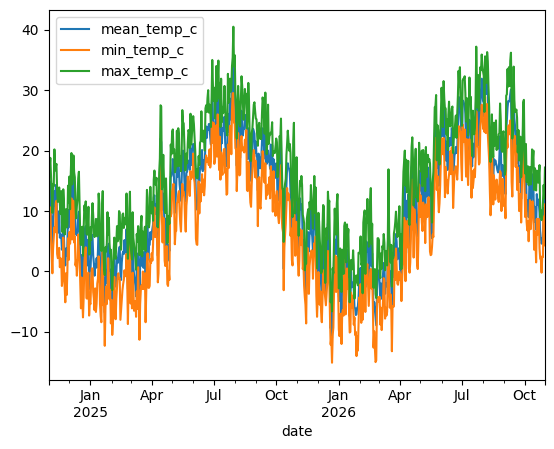

In [ ]:
df.plot();

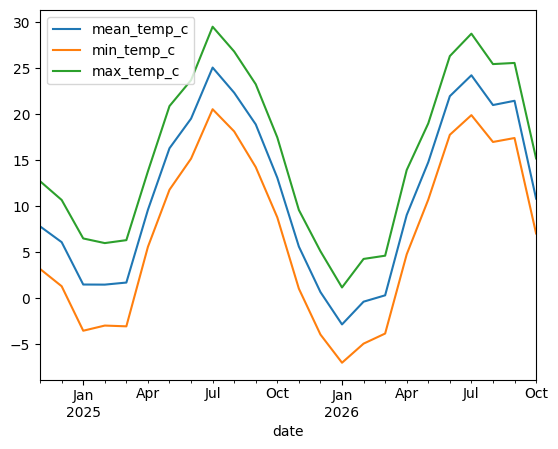

In [ ]:
df.resample('ME').mean().plot();

### Part 1 : CNN Predictions

Implement a CNN taking in 30 days of mean temperatures as input and predicting the next day's mean temperature.

Before training the CNN, use it to predict the temperatures for 2026-10-01 through 2026-10-31.
Use the actual data as inputs; don't try to blend actual and predicted inputs.
Save the mean squared error.

In [ ]:
import torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader

class CNN(nn.Module):
    def __init__(self):
        super().__init__()

        self.network = nn.Sequential(
            nn.Conv1d(in_channels=1, out_channels=16, kernel_size=3),
            nn.ReLU(),
            nn.Conv1d(in_channels=16, out_channels=32, kernel_size=3),
            nn.ReLU(),
            nn.Flatten(),
            nn.Linear(32 * 26, 32),
            nn.ReLU(),
            nn.Linear(32, 1)
        )

    def forward(self, x):
        return self.network(x)



df = df.sort_index()

temps = torch.tensor(
    df["mean_temp_c"].to_numpy(),
    dtype=torch.float32
)

window_size = 30

X = torch.stack([
    temps[i:i + window_size]
    for i in range(len(temps) - window_size)
]).unsqueeze(1)

y = temps[window_size:].unsqueeze(1)
target_dates = df.index[window_size:]

train_mask = torch.tensor(target_dates < pd.Timestamp("2026-10-01"))
test_mask = torch.tensor(
    (target_dates >= pd.Timestamp("2026-10-01")) &
    (target_dates <= pd.Timestamp("2026-10-31"))
)

X_train, y_train = X[train_mask], y[train_mask]
X_test, y_test = X[test_mask], y[test_mask]

model = CNN()
criterion = nn.MSELoss()

model.eval()
with torch.no_grad():
    initial_predictions = model(X_test)
    cnn_initialized_mse = criterion(initial_predictions, y_test).item()

print("MSE:", cnn_initialized_mse)
#MSE: 127.45682525634766

MSE: 127.45682525634766


Train it to predict dates before 2026-10-01.
Always use the actual data provided for the inputs.

In [9]:
train_loader = DataLoader(
    TensorDataset(X_train, y_train),
    batch_size=32,
    shuffle=True
)

optimizer = torch.optim.Adam(model.parameters(), lr=0.001)

for epoch in range(100):
    model.train()
    total_loss = 0.0

    for inputs, targets in train_loader:
        optimizer.zero_grad()

        predictions = model(inputs)
        loss = criterion(predictions, targets)

        loss.backward()
        optimizer.step()

        total_loss += loss.item() * inputs.size(0)


train_mse = total_loss/len(X_train)
print(train_mse)

1.0865617459486774


Generate predictions for 2026-10-01 through 2026-10-31 using your CNN.
Use the actual data as inputs; don't try to predictions blending actual and predicted inputs.
Save them in a file `cnn-predictions.tsv` with columns `date` and `temp_pred`.

In [ ]:
model.eval()

with torch.no_grad():
    cnn_predictions = model(X_test)
    cnn_trained_mse = criterion(cnn_predictions, y_test).item()

cnn_results = pd.DataFrame({
    "date": target_dates[test_mask.numpy()].strftime("%Y-%m-%d"),
    "temp_pred": cnn_predictions.squeeze(1).numpy()
})

cnn_results.to_csv("cnn-predictions.tsv", sep="\t", index=False)

,date,temp_pred
0,2026-10-01,12.994348
1,2026-10-02,17.395115
2,2026-10-03,13.381619
3,2026-10-04,20.701540
4,2026-10-05,17.802351


Plot your predictions against the actual values to spot check your prediction quality.

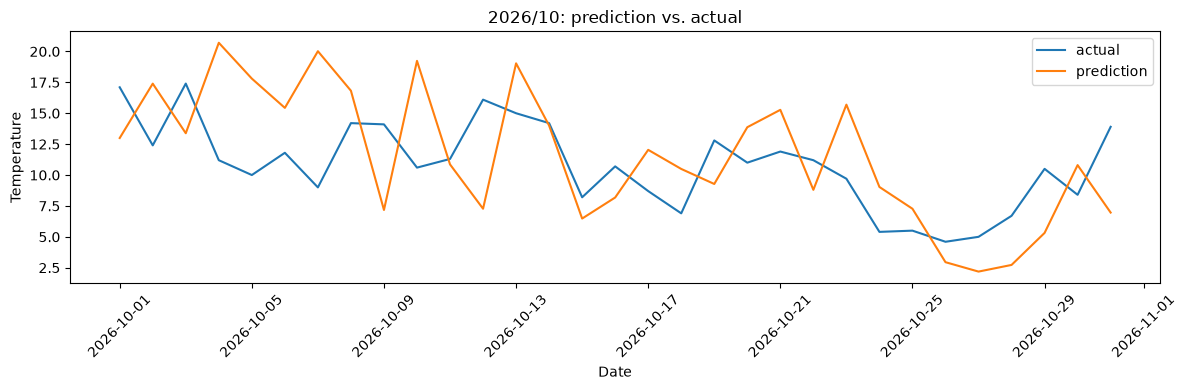

In [12]:
import matplotlib.pyplot as plt

dates = target_dates[test_mask.numpy()]

plt.figure(figsize=(12, 4))
plt.plot(dates, y_test.squeeze(1).numpy(), label="actual")
plt.plot(dates, cnn_predictions.squeeze(1).numpy(), label="prediction")
plt.xlabel("Date")
plt.ylabel("Temperature")
plt.title("2026/10: prediction vs. actual")
plt.legend()
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

### Part 2

Implement an RNN taking in all previous days of input and predicting the next days mean temperature.
The only input at each step should be the mean temperature.

Before training the RNN, use it to predict the temperatures for 2026-10-01 through 2026-10-31.
Use the actual data as inputs; don't try to blend actual and predicted inputs.
Save the mean squared error.

In [ ]:
class RNN(nn.Module):
    def __init__(self):
        super().__init__()

        self.rnn = nn.RNN(
            input_size=1, #feature: mean temp
            hidden_size=32,
            batch_first=True
        )
        self.linear = nn.Linear(32, 1)

    def forward(self, x):
        hidden_states, final_hidden = self.rnn(x)
        return self.linear(hidden_states)



df = df.sort_index()
rnn_temps = torch.tensor(
    df["mean_temp_c"].to_numpy(),
    dtype=torch.float32
)

cutoff = pd.Timestamp("2026-10-01")
n_train_days = int((df.index < cutoff).sum())

temp_mean = rnn_temps[:n_train_days].mean()
temp_std = rnn_temps[:n_train_days].std()

normalized = (rnn_temps - temp_mean) / temp_std

X_all = normalized[:-1].reshape(1, -1, 1)
y_all = normalized[1:].reshape(1, -1, 1)

target_dates_rnn = df.index[1:]

X_train_rnn = X_all[:, :n_train_days - 1, :]
y_train_rnn = y_all[:, :n_train_days - 1, :]

october_mask = torch.tensor(
    (target_dates_rnn >= pd.Timestamp("2026-10-01")) &
    (target_dates_rnn <= pd.Timestamp("2026-10-31"))
)

actual_october = rnn_temps[1:][october_mask]

rnn_model = RNN()
criterion_rnn = nn.MSELoss()

rnn_model.eval()

with torch.no_grad():
    outputs = rnn_model(X_all).reshape(-1)
    predictions = outputs[october_mask] * temp_std + temp_mean
    mse = criterion_rnn(predictions, actual_october).item()


print("MSE:", mse)
#MSE: 11.0986


MSE: 11.098612785339355


Generate predictions for 2026-10-01 through 2026-10-31 using your RNN.
Save them in a file `rnn-predictions.tsv` with columns `date` and `temp_pred`.

In [17]:
optimizer_rnn = torch.optim.Adam(rnn_model.parameters(), lr=0.001)

for epoch in range(300):
    rnn_model.train()
    optimizer_rnn.zero_grad()

    predictions = rnn_model(X_train_rnn)
    loss = criterion_rnn(predictions, y_train_rnn)

    loss.backward()
    torch.nn.utils.clip_grad_norm_(rnn_model.parameters(), max_norm=1.0)
    optimizer_rnn.step()

rnn_model.eval()

with torch.no_grad():
    outputs = rnn_model(X_all).reshape(-1)
    predictions = outputs[october_mask] * temp_std + temp_mean

rnn_dates = target_dates_rnn[october_mask.numpy()]

rnn_results = pd.DataFrame({
    "date": rnn_dates.strftime("%Y-%m-%d"),
    "temp_pred": predictions.numpy()
})

rnn_results.to_csv("rnn-predictions.tsv", sep="\t", index=False)

Plot your predictions against the actual values to spot check your prediction quality.

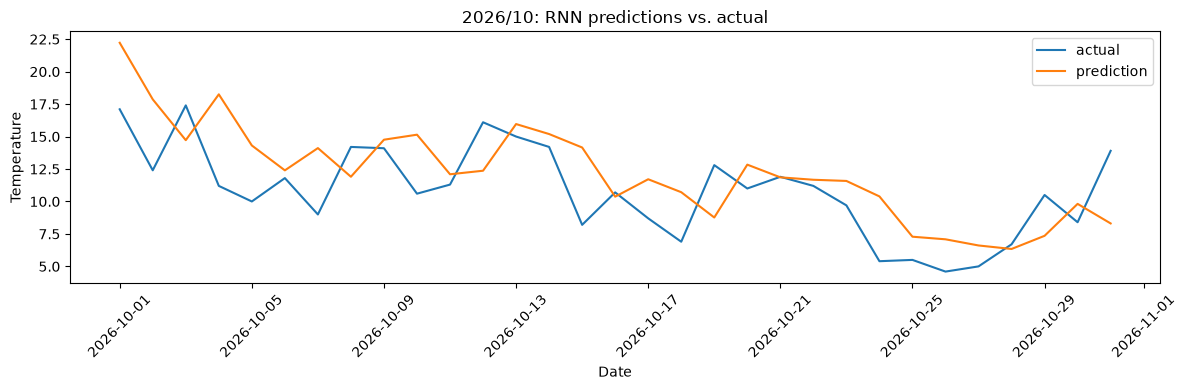

In [18]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 4))
plt.plot(rnn_dates, actual_october.numpy(), label="actual")
plt.plot(rnn_dates, predictions.numpy(), label="prediction")
plt.xlabel("Date")
plt.ylabel("Temperature")
plt.title("2026/10: RNN predictions vs. actual")
plt.legend()
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

## Part 3 : Training Improvements

Write a file `training-improvements.tsv` with 3 columns, `architecture`, `initialized_mse`, `trained_mse`.
There should be two rows with `architecture` set to `cnn` or `rnn` and the two MSE columns should have the mean squared error from before and after your training was done.

## Gradescope Submission

Submit both your Jupyter notebook, `cnn-predictions.tsv` and `rnn-predictions.tsv` in Gradescope.

Make sure to check the Gradescope autograder results after submission.
**You will not receive credit for missing or misnamed files.**